# 20 Model 5, stage 3: does attentive pooling help the classifier head?

**Where this sits.** Stages 1 and 2 (notebooks 18 and 19) kept the plain ST-GCN backbone with velocity input,
the balanced sampler and cross entropy. Stage 3 changes only how the final features are pooled.

**What is being tested.** ST-GCN's head averages the last feature map over every frame and every joint with equal
weight, so a frame of the follow through counts as much as the frame of contact, and an irrelevant joint as much
as the hitting wrist. The attentive head learns a weighting instead. The scores come from a single 1x1 convolution
on the last feature map (257 extra parameters), followed by a softmax over the pooled positions.

The head is built to start as exactly the baseline: the score weights and bias are initialised to zero, so the
softmax is uniform and the output equals global average pooling with the same classifier. Training can then move
the weights away from uniform, and anything else about the model is unchanged. The smoke test checks this
equivalence numerically.

| arm | pooling | what the attention covers |
|---|---|---|
| `control` | global average | the stage 1 control, **reused** (same seeds, same code), not re-run |
| `attn_time` | learned weights over time | one weight per (downsampled) frame, joints averaged first |
| `attn_joint_time` | learned weights over time and joints | one weight per frame and joint position |

**Protocol.** Validation only, seeds 77 and 88 (the same as stages 1 and 2, so the comparison is paired). The
recipe, sampler and loss are those selected in stage 2 (the balanced sampler with cross entropy). Validation has
now been used for three stages, so small gains carry more selection optimism than in stage 1.

**Decision rule, fixed before running.** Same as the earlier stages. An arm is kept if its mean validation top 1
is at least 0.5 points above the control and its mean validation MCA is not more than 1 point lower; the best
qualifying arm is chosen, preferring fewer changes within 0.3 points; if none qualify the average pooling head is
kept.

**Inspection.** The mean attention over validation clips is saved for each arm and plotted by frame and by joint.
This is descriptive: it shows where the model looks, not that looking there is what makes it right.

Logs to `BadmintonPoseAnalysis/experiments/model5_stage3_pooling`.

In [1]:
import os
os.environ["CUBLAS_WORKSPACE_CONFIG"] = ":4096:8"

import json
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from clearml import Task

REPO = os.environ.get("BADMINTON_REPO", "/workspace/badminton-honours-project")
DATA = os.environ.get("BADMINTON_DATA", "/workspace/data")
OUTPUTS = os.environ.get("BADMINTON_OUTPUTS", "/workspace/outputs")
sys.path.insert(0, REPO)
import dataset as ds
import losses
from models import stgcn as stgcn_model
import training as tr

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(torch.__version__, device, torch.cuda.get_device_name(0) if device.type == "cuda" else "")
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.spines.top": False, "axes.spines.right": False})

2.1.0+cu118 cuda NVIDIA GeForce RTX 4090


In [2]:
PROJECT = "BadmintonPoseAnalysis/experiments/model5_stage3_pooling"
KEYPOINTS = f"{DATA}/keypoints_interp"
OUT = f"{OUTPUTS}/experiments/model5_stage3_pooling"
STAGE1_OUT = f"{OUTPUTS}/experiments/model5_stage1_graph"
os.makedirs(OUT, exist_ok=True)

SEEDS = [77, 88]
SPLITS = ("train", "val")          # the test set is never evaluated while tuning
NORMALISATION, USE_COURT, USE_VELOCITY = "body", True, True
NUM_WORKERS, EVAL_WORKERS = 20, 8
RARE_THRESHOLD = int(os.environ.get("RARE_THRESHOLD", 150))
MIN_GAIN, MAX_MCA_DROP, TIE = 0.005, 0.01, 0.003

ARMS = {"attn_time": "attn_time", "attn_joint_time": "attn_joint_time"}      # arm name -> head
ORDER = ["control", *ARMS]
N_CHANGES = {"control": 0, "attn_time": 1, "attn_joint_time": 1}
JOINTS = ["nose", "L eye", "R eye", "L ear", "R ear", "L shoulder", "R shoulder", "L elbow", "R elbow",
          "L wrist", "R wrist", "L hip", "R hip", "L knee", "R knee", "L ankle", "R ankle"]

with open(f"{REPO}/configs/stgcn_recipe.json") as f:
    RECIPE = json.load(f)
with open(f"{REPO}/configs/model5_stage1.json") as f:
    STAGE1 = json.load(f)
with open(f"{REPO}/configs/model5_stage2.json") as f:
    STAGE2 = json.load(f)
BACKBONE, VEL_SCALE = STAGE1["backbone_options"], STAGE1["velocity_scale"]
assert STAGE2["selected"] == "control", (
    f"stage 2 selected {STAGE2['selected']!r}; this notebook reuses the stage 1 control, which is only valid when "
    "stage 2 kept the balanced sampler with cross entropy. Re-run a control with the stage 2 setting first.")
print("backbone options:", BACKBONE or "none", "| sampling:", STAGE2["sampling"], "| loss:", STAGE2["loss"])

backbone options: none | sampling: balanced | loss: cross_entropy


In [3]:
manifest = ds.load_filtered_manifest(f"{DATA}/split_manifest.csv", f"{DATA}/extraction_log.csv",
                                     f"{DATA}/keypoints_interp_log.csv", RECIPE["min_native_frames"])
class_names = sorted(manifest["class_name"].unique())
class_to_id = {c: i for i, c in enumerate(class_names)}
K = len(class_names)
short = [c.split("_", 1)[1] for c in class_names]
split_hash = open(f"{DATA}/split_manifest.sha256").read().split()[0]
train = manifest[manifest["split"] == "train"].reset_index(drop=True)
train_counts = train["class_name"].value_counts().reindex(class_names)
rare_ids = [class_to_id[c] for c in class_names if train_counts[c] < RARE_THRESHOLD]
common_ids = [k for k in range(K) if k not in rare_ids]

in_channels = stgcn_model.n_channels(USE_COURT, USE_VELOCITY)
forward = stgcn_model.make_forward(USE_COURT, USE_VELOCITY, VEL_SCALE)

manual review: dropped 4 clips
short clip rule: dropped 4 train clips with fewer than 5 real frames
7810 clips remain (train 6247, test 782, val 781)


## Smoke test

Run alone first. The important check is the first one: with the attention weights at their initial value, each
attentive head must give the same logits as the plain head on the same features and classifier. If that
fails, any difference found later could not be attributed to what attention learns.

In [4]:
tr.seed_everything(0)
loaders = tr.build_loaders(manifest, KEYPOINTS, class_to_id, RECIPE["augmentation"], NORMALISATION, seed=0,
                           batch_size=RECIPE["batch_size"], target_per_class=RECIPE["target_per_class"],
                           num_workers=2, eval_workers=2)
batch = next(iter(loaders["train"]))

base = stgcn_model.build_stgcn(in_channels, K, head="avg", **BACKBONE).to(device).eval()
base_params = sum(p.numel() for p in base.parameters())
for arm, head in ARMS.items():
    model = stgcn_model.build_stgcn(in_channels, K, head=head, **BACKBONE).to(device)
    missing = model.load_state_dict(base.state_dict(), strict=False)
    assert not missing.unexpected_keys and all(k.startswith("cls_head.attn") for k in missing.missing_keys), missing
    model.eval()
    with torch.no_grad():
        a, b = forward(base, batch, device), forward(model, batch, device)
    assert torch.allclose(a, b, atol=1e-4), f"{arm}: attentive head at initialisation differs from average pooling"
    attn = model.cls_head.last_attn
    assert torch.allclose(attn.sum(dim=(1, 2)), torch.ones(attn.shape[0], device=attn.device), atol=1e-4)
    assert attn.std() < 1e-6, "attention should start uniform"
    model.train()
    nn.CrossEntropyLoss()(forward(model, batch, device), batch["label"].to(device)).backward()
    assert model.cls_head.attn.weight.grad is not None
    extra = sum(p.numel() for p in model.parameters()) - base_params
    print(f"{arm:16s} equals average pooling at initialisation (max logit difference {(a - b).abs().max().item():.1e}), "
          f"{extra} extra parameters, attention map {tuple(attn.shape[1:])}")
    del model
del base, loaders

control = pd.read_csv(f"{STAGE1_OUT}/results.csv")
control = control[control["config"] == "control"]
assert sorted(control["seed"]) == sorted(SEEDS)
print("stage 1 control found for seeds", SEEDS)
print("smoke test passed")

attn_time        equals average pooling at initialisation (max logit difference 1.5e-08), 257 extra parameters, attention map (8, 17)
attn_joint_time  equals average pooling at initialisation (max logit difference 1.5e-08), 257 extra parameters, attention map (8, 17)
stage 1 control found for seeds [77, 88]
smoke test passed


## Runs

Two arms, two seeds each, four runs. After each run the mean attention over the validation clips is saved next to
the other outputs. Finished runs are skipped.

In [5]:
results_path = f"{OUT}/results.csv"


def load_results():
    return pd.read_csv(results_path) if os.path.exists(results_path) else pd.DataFrame(columns=["config", "seed"])


@torch.no_grad()
def mean_attention(model, loader):
    model.eval()
    total, count = None, 0
    for batch in loader:
        forward(model, batch, device)
        a = model.cls_head.last_attn.float().cpu()                     # (N, T, V), sums to 1 per clip
        total = a.sum(0) if total is None else total + a.sum(0)
        count += a.shape[0]
    return (total / count).numpy()


def run_arm(name, head, seed):
    done = load_results()
    if ((done["config"] == name) & (done["seed"] == seed)).any():
        print(f"skip {name} seed {seed}, already done")
        return
    run_name = f"model5s3_{name}_s{seed}"
    print(f"\n=== {run_name}  head {head} ===")
    tr.seed_everything(seed)

    task = Task.init(project_name=PROJECT, task_name=run_name, task_type=Task.TaskTypes.training,
                     tags=["model5", "stage3", name, f"seed{seed}"], reuse_last_task_id=False,
                     auto_connect_frameworks={"matplotlib": False, "pytorch": False})
    task.connect({**RECIPE, "arm": name, "head": head, "backbone_options": BACKBONE, "input": "body_court_velocity",
                  "in_channels": in_channels, "velocity_scale": VEL_SCALE, "seed": seed, "keypoints": KEYPOINTS,
                  "split_sha256": split_hash, "evaluated_splits": list(SPLITS)})

    loaders = tr.build_loaders(manifest, KEYPOINTS, class_to_id, RECIPE["augmentation"], NORMALISATION, seed=seed,
                               batch_size=RECIPE["batch_size"], target_per_class=RECIPE["target_per_class"],
                               num_workers=NUM_WORKERS, eval_workers=EVAL_WORKERS)
    model = stgcn_model.build_stgcn(in_channels, K, head=head, **BACKBONE).to(device)
    optimizer = torch.optim.SGD(model.parameters(), lr=RECIPE["lr"], momentum=RECIPE["momentum"],
                                weight_decay=RECIPE["weight_decay"])
    scheduler = torch.optim.lr_scheduler.StepLR(optimizer, step_size=10, gamma=RECIPE["gamma"])
    criterion = nn.CrossEntropyLoss(label_smoothing=RECIPE["label_smoothing"])

    _, history, best_epoch = tr.train_model(model, forward, loaders, optimizer, scheduler, criterion, device,
                                            task.get_logger(), num_epochs=RECIPE["num_epochs"],
                                            patience=RECIPE.get("patience", 20), select_metric=RECIPE["select_metric"],
                                            splits=SPLITS)
    metrics = tr.report_run(task, model, forward, loaders, class_names, device, history, best_epoch,
                            out_dir=f"{OUT}/{run_name}", run_name=run_name, splits=SPLITS, show=False,
                            extra={"config": name, "seed": seed, "head": head})
    np.save(f"{OUT}/{run_name}/{run_name}_attention.npy", mean_attention(model, loaders["val"]))
    task.close()

    pd.concat([done, pd.DataFrame([metrics])], ignore_index=True).to_csv(results_path, index=False)
    del model, loaders
    torch.cuda.empty_cache()


for name, head in ARMS.items():
    for seed in SEEDS:
        run_arm(name, head, seed)


=== model5s3_attn_time_s77  head attn_time ===
ClearML Task: created new task id=fe6c3909de7d46a79320a0dc385444f8
2026-10-07 05:36:14,318 - clearml.Repository Detection - WARNING - Failed accessing the jupyter server(s): []
ClearML results page: https://app.clear.ml/projects/33c8ab04aac8411eba32a41ed917f1a2/tasks/fe6c3909de7d46a79320a0dc385444f8/output/log
epoch   0  loss 1.915  train 0.557  val 0.534 (mca 0.461)  *
epoch   1  loss 1.430  train 0.607  val 0.598 (mca 0.492)  *
epoch   2  loss 1.279  train 0.674  val 0.653 (mca 0.500)  *
epoch   4  loss 1.154  train 0.675  val 0.663 (mca 0.572)  *
epoch   5  loss 1.133  train 0.690  val 0.677 (mca 0.584)  *
epoch   6  loss 1.105  train 0.691  val 0.680 (mca 0.572)  *
epoch  10  loss 0.813  train 0.789  val 0.707 (mca 0.624)  *
epoch  11  loss 0.697  train 0.808  val 0.714 (mca 0.625)  *
epoch  13  loss 0.605  train 0.838  val 0.722 (mca 0.632)  *
epoch  14  loss 0.571  train 0.855  val 0.729 (mca 0.639)  *
epoch  15  loss 0.527  train 0

███████████████████████████████ 100% | 11.67/11.67 MB [00:01<00:00,  7.97MB/s]: 



=== model5s3_attn_time_s88  head attn_time ===


Failed accessing the jupyter server(s): []


ClearML Task: created new task id=c84d30b636a547948a944a1064e63eb8
ClearML results page: https://app.clear.ml/projects/33c8ab04aac8411eba32a41ed917f1a2/tasks/c84d30b636a547948a944a1064e63eb8/output/log
epoch   0  loss 1.867  train 0.519  val 0.521 (mca 0.426)  *
epoch   1  loss 1.437  train 0.601  val 0.577 (mca 0.483)  *
epoch   2  loss 1.293  train 0.680  val 0.649 (mca 0.548)  *
epoch   4  loss 1.133  train 0.711  val 0.694 (mca 0.611)  *
epoch   5  loss 1.108  train 0.711  val 0.675 (mca 0.566)
epoch  10  loss 0.794  train 0.794  val 0.703 (mca 0.609)  *
epoch  11  loss 0.684  train 0.808  val 0.708 (mca 0.619)  *
epoch  13  loss 0.614  train 0.838  val 0.717 (mca 0.639)  *
epoch  15  loss 0.524  train 0.863  val 0.734 (mca 0.644)  *
epoch  19  loss 0.432  train 0.891  val 0.735 (mca 0.648)  *
epoch  20  loss 0.338  train 0.928  val 0.745 (mca 0.658)  *
epoch  25  loss 0.235  train 0.957  val 0.745 (mca 0.637)
epoch  30  loss 0.186  train 0.976  val 0.738 (mca 0.636)
epoch  35  los

...

███████████████████████████████ 100% | 11.67/11.67 MB [00:01<00:00,  8.02MB/s]: 



=== model5s3_attn_joint_time_s88  head attn_joint_time ===


Failed accessing the jupyter server(s): []


ClearML Task: created new task id=19b59dd1206e4298b69fa082475dec7e
ClearML results page: https://app.clear.ml/projects/33c8ab04aac8411eba32a41ed917f1a2/tasks/19b59dd1206e4298b69fa082475dec7e/output/log
epoch   0  loss 1.946  train 0.498  val 0.501 (mca 0.339)  *
epoch   1  loss 1.508  train 0.559  val 0.569 (mca 0.485)  *
epoch   2  loss 1.344  train 0.665  val 0.641 (mca 0.524)  *
epoch   3  loss 1.251  train 0.670  val 0.647 (mca 0.596)  *
epoch   4  loss 1.174  train 0.684  val 0.680 (mca 0.587)  *
epoch   5  loss 1.140  train 0.703  val 0.684 (mca 0.588)  *
epoch  10  loss 0.778  train 0.798  val 0.714 (mca 0.635)  *
epoch  13  loss 0.544  train 0.856  val 0.718 (mca 0.660)  *
epoch  14  loss 0.502  train 0.867  val 0.721 (mca 0.644)  *
epoch  15  loss 0.461  train 0.874  val 0.717 (mca 0.642)
epoch  18  loss 0.373  train 0.904  val 0.735 (mca 0.647)  *
epoch  20  loss 0.248  train 0.956  val 0.731 (mca 0.655)
epoch  22  loss 0.193  train 0.969  val 0.744 (mca 0.659)  *
epoch  24  

███████████████████████████████ 100% | 11.67/11.67 MB [00:01<00:00,  6.67MB/s]: 


## Selection

Mean over the two seeds, validation only. Recall on the limited sample and common classes comes from the saved
per clip predictions of every arm, the stage 1 control included.

In [6]:
def val_recall(path):
    p = pd.read_csv(path)
    p = p[p["split"] == "val"]
    labels, preds = p["label"].map(class_to_id).to_numpy(), p["pred"].map(class_to_id).to_numpy()
    rec = np.array([(preds[labels == k] == k).mean() for k in range(K)])
    return rec[rare_ids].mean(), rec[common_ids].mean()


def run_dir(arm, seed):
    return (f"{STAGE1_OUT}/model5s1_control_s{seed}/model5s1_control_s{seed}" if arm == "control"
            else f"{OUT}/model5s3_{arm}_s{seed}/model5s3_{arm}_s{seed}")


results = pd.concat([control.assign(config="control"), load_results()], ignore_index=True)
results["limited_recall"], results["common_recall"] = zip(*[val_recall(f"{run_dir(r.config, r.seed)}_predictions.csv")
                                                          for r in results.itertuples()])
g = results.groupby("config")
table = pd.DataFrame({
    "val top1": g["val_top1"].mean(), "val top1 std": g["val_top1"].std().fillna(0),
    "val top5": g["val_top5"].mean(), "val mca": g["val_mca"].mean(), "val macro f1": g["val_macro_f1"].mean(),
    "limited recall": g["limited_recall"].mean(), "common recall": g["common_recall"].mean(),
    "train val gap": g["train_val_gap"].mean(), "best epoch": g["best_epoch"].mean(),
    "parameters": g["parameters"].first(), "seeds": g["seed"].count(),
}).loc[ORDER]
base = table.loc["control"]
table["d top1"] = table["val top1"] - base["val top1"]
table["d mca"] = table["val mca"] - base["val mca"]
table["passes"] = [(n != "control") and (r["d top1"] >= MIN_GAIN) and (r["d mca"] >= -MAX_MCA_DROP) for n, r in table.iterrows()]

eligible = ["control"] + [n for n in ARMS if table.loc[n, "passes"]]
best = table.loc[eligible, "val top1"].max()
close = [n for n in eligible if best - table.loc[n, "val top1"] <= TIE]
selected = min(close, key=lambda n: (N_CHANGES[n], -table.loc[n, "val top1"]))
print("arms passing the rule:", [n for n in ARMS if table.loc[n, "passes"]] or "none")
print("selected:", selected)

pct = ["val top1", "val top1 std", "val top5", "val mca", "val macro f1", "limited recall", "common recall",
       "train val gap", "d top1", "d mca"]
show = table.assign(**{c: (100 * table[c]).round(2) for c in pct}).round({"best epoch": 1})
show["selected"] = [n == selected for n in show.index]
show

arms passing the rule: none
selected: control


,val top1,val top1 std,val top5,val mca,val macro f1,limited recall,common recall,train val gap,best epoch,parameters,seeds,d top1,d mca,passes,selected
config,,,,,,,,,,,,,,,
control,76.76,0.45,95.20,67.75,68.22,61.55,72.71,20.02,34.5,3028735.0,2,0.00,0.00,False,True
attn_time,74.52,0.00,95.39,65.52,66.08,59.93,69.99,19.48,21.5,3028992.0,2,-2.24,-2.23,False,False
attn_joint_time,74.26,1.27,94.75,65.75,66.43,60.81,69.70,24.61,42.0,3028992.0,2,-2.50,-2.01,False,False


Failed accessing the jupyter server(s): []


ClearML Task: created new task id=33fda4c5f7ef46298dafb7c20ce422e5
ClearML results page: https://app.clear.ml/projects/33c8ab04aac8411eba32a41ed917f1a2/tasks/33fda4c5f7ef46298dafb7c20ce422e5/output/log


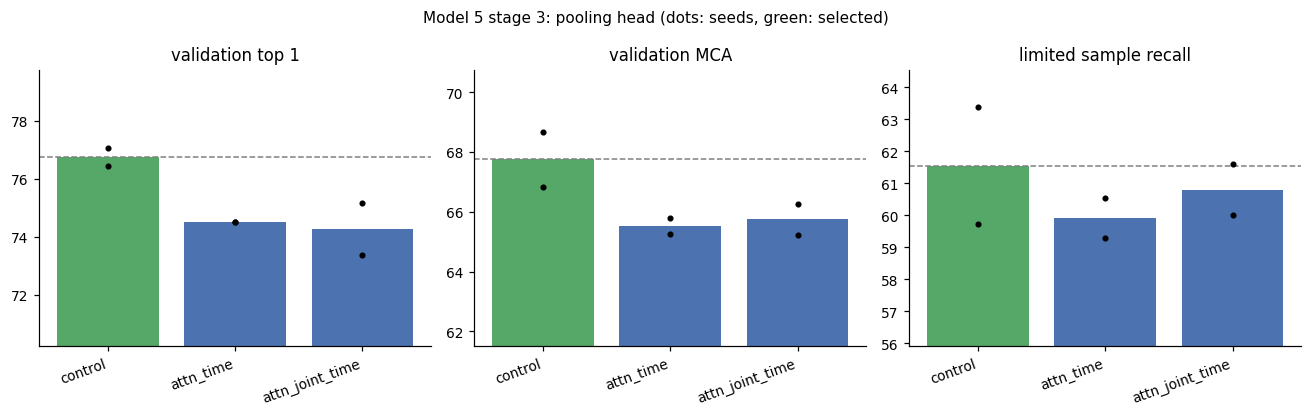

In [7]:
task = Task.init(project_name=PROJECT, task_name="stage3_selection", task_type=Task.TaskTypes.qc,
                 tags=["model5", "stage3", "summary"], reuse_last_task_id=False, auto_connect_frameworks={"matplotlib": False})
slog = task.get_logger()
task.connect({**RECIPE, "arms": ARMS, "seeds": SEEDS, "backbone_options": BACKBONE, "velocity_scale": VEL_SCALE,
              "rule": {"min_gain": MIN_GAIN, "max_mca_drop": MAX_MCA_DROP, "tie": TIE}, "rare_threshold": RARE_THRESHOLD})
slog.report_table("stage 3 comparison (validation, mean over tuning seeds)", "val", iteration=0,
                  table_plot=show.reset_index().rename(columns={"index": "arm"}))
slog.report_single_value("selected_val_top1", float(table.loc[selected, "val top1"]))
slog.report_single_value("control_val_top1", float(base["val top1"]))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.8))
x = np.arange(len(ORDER))
for ax, metric, title in zip(axes, ["val_top1", "val_mca", "limited_recall"],
                             ["validation top 1", "validation MCA", "limited sample recall"]):
    means = [results.loc[results["config"] == n, metric].mean() for n in ORDER]
    colours = ["#55a868" if n == selected else "#b0b0b0" if n == "control" else "#4c72b0" for n in ORDER]
    ax.bar(x, 100 * np.array(means), color=colours)
    for i, n in enumerate(ORDER):
        ax.scatter(np.full(len(SEEDS), i), 100 * results.loc[results["config"] == n, metric], color="black", s=9, zorder=3)
    ax.axhline(100 * results.loc[results["config"] == "control", metric].mean(), color="grey", ls="--", lw=1)
    ax.set_xticks(x, ORDER, rotation=20, ha="right")
    ax.set_ylim(100 * min(means) - 4, 100 * max(means) + 3)
    ax.set_title(title)
fig.suptitle("Model 5 stage 3: pooling head (dots: seeds, green: selected)", fontsize=10)
fig.tight_layout()
slog.report_matplotlib_figure("stage 3 comparison", "val", figure=fig, iteration=0, report_interactive=False)
plt.show()

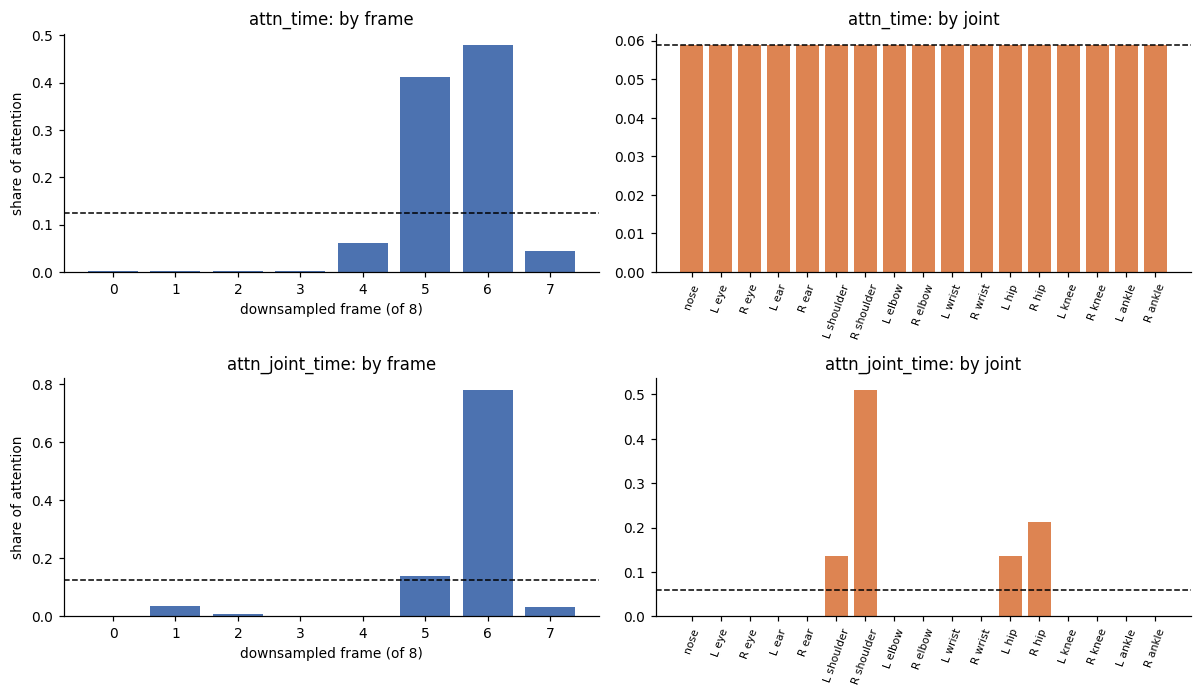

In [8]:
# where the attention goes: mean over validation clips and both seeds (uniform would be the dashed line)
fig, axes = plt.subplots(len(ARMS), 2, figsize=(11, 3.2 * len(ARMS)), squeeze=False)
for row, arm in enumerate(ARMS):
    maps = np.mean([np.load(f"{OUT}/model5s3_{arm}_s{s}/model5s3_{arm}_s{s}_attention.npy") for s in SEEDS], axis=0)   # (T, V)
    T, V = maps.shape
    axes[row, 0].bar(range(T), maps.sum(axis=1), color="#4c72b0")
    axes[row, 0].axhline(1 / T, color="black", ls="--", lw=1)
    axes[row, 0].set_xlabel("downsampled frame (of %d)" % T)
    axes[row, 0].set_ylabel("share of attention")
    axes[row, 0].set_title(f"{arm}: by frame")
    axes[row, 1].bar(range(V), maps.sum(axis=0), color="#dd8452")
    axes[row, 1].axhline(1 / V, color="black", ls="--", lw=1)
    axes[row, 1].set_xticks(range(V), JOINTS, rotation=70, fontsize=7)
    axes[row, 1].set_title(f"{arm}: by joint")
fig.tight_layout()
slog.report_matplotlib_figure("mean attention", "val", figure=fig, iteration=0, report_interactive=False)
plt.show()

In [9]:
stage = {"stage": 3, "selected": selected, "head": "avg" if selected == "control" else ARMS[selected],
         "backbone_options": BACKBONE, "sampling": STAGE2["sampling"], "loss": STAGE2["loss"], "tau": STAGE2["tau"],
         "input": "body_court_velocity", "velocity_scale": VEL_SCALE,
         "tuning": {"seeds": SEEDS, "val_top1": round(float(table.loc[selected, "val top1"]), 4),
                    "val_mca": round(float(table.loc[selected, "val mca"]), 4),
                    "control_val_top1": round(float(base["val top1"]), 4), "control_val_mca": round(float(base["val mca"]), 4)}}
with open(f"{REPO}/configs/model5_stage3.json", "w") as f:
    json.dump(stage, f, indent=2)
task.upload_artifact("selected_head", artifact_object=f"{REPO}/configs/model5_stage3.json")
task.upload_artifact("results", artifact_object=results_path)
task.close()
stage

{'stage': 3,
 'selected': 'control',
 'head': 'avg',
 'backbone_options': {},
 'sampling': 'balanced',
 'loss': 'cross_entropy',
 'tau': 0.0,
 'input': 'body_court_velocity',
 'velocity_scale': 28.841716766357422,
 'tuning': {'seeds': [77, 88],
  'val_top1': 0.7676,
  'val_mca': 0.6775,
  'control_val_top1': 0.7676,
  'control_val_mca': 0.6775}}

## Reading the result

- Apply the stated rule to the table above. A pass means "carry into the final five seed comparison", not a
  finding; two seeds cannot separate differences under about a point.
- If nothing passes, global average pooling is already adequate for this feature map: after nine graph and
  temporal convolution stages, each position already summarises a large receptive field, so reweighting them has
  little left to add.
- The attention plots are descriptive. A learned weighting concentrated on a few frames or on the wrists would
  agree with how shots are played, but it would not show that those positions are what the model needs, and an
  attention profile close to uniform means the head barely moved from its starting point.
- Whatever is selected here, together with the velocity input, defines model 5 as built so far. The remaining
  planned experiment is pretraining, kept separate.